# 01C — Prompted LLM Classifier

Five-class conflict classification using GPT-4o. The classifier uses the question and retrieved document titles and short texts, without access to the gold label. The classification prompt and configuration are shared with `02_rag_generation_fourway.ipynb`.

## 1. Setup

Choose `validation_smoke`, `validation_full`, or `final_test` using `RUN_MODE`. API calls are controlled by `RUN_API`, and test evaluation requires `ALLOW_FINAL_TEST=True`.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import random

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

IS_KAGGLE = Path("/kaggle/input").is_dir()
OUTPUT_DIR = Path("/kaggle/working") if IS_KAGGLE else Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# Use only the current working directory; do not search parent or subfolders.
# Keep the notebook and the two data files in this directory.
DATA_DIR = Path.cwd()
DATA_PATH = DATA_DIR / "conflicts_621.jsonl"
SPLIT_PATH = DATA_DIR / "conflicts_original_eval_split.json"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found in current working directory: {DATA_PATH}")
if not SPLIT_PATH.is_file():
    raise FileNotFoundError(f"Split manifest not found in current working directory: {SPLIT_PATH}")
print("Working directory:", DATA_DIR)
print("Dataset:", DATA_PATH)
print("Split:", SPLIT_PATH)
print("Output:", OUTPUT_DIR)

import time
import matplotlib.pyplot as plt
from getpass import getpass
from IPython.display import display
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

LLM_MODEL = "gpt-4o-2024-08-06"
LLM_CLASSIFIER_PROMPT_VERSION = "question_title_short_text"
RUN_MODE = "final_test"  # validation_smoke / validation_full / final_test
VALIDATION_SMOKE_PER_CLASS = 1
RUN_API = True  # Enable to request missing predictions (paid).
ALLOW_FINAL_TEST = True

Working directory: /Users/GXM/03-trimester 2/AIML339/Assignment/7
Dataset: /Users/GXM/03-trimester 2/AIML339/Assignment/7/conflicts_621.jsonl
Split: /Users/GXM/03-trimester 2/AIML339/Assignment/7/conflicts_original_eval_split.json
Output: /Users/GXM/03-trimester 2/AIML339/Assignment/7


## 2. Dataset and frozen split

In [2]:
LABELS = [
    "No conflict",
    "Complementary information",
    "Conflicting opinions and research outcomes",
    "Conflict due to outdated information",
    "Conflict due to misinformation",
]
label2id = {name: i for i, name in enumerate(LABELS)}
id2label = {i: name for name, i in label2id.items()}

with DATA_PATH.open(encoding="utf-8") as f:
    data = [json.loads(line) for line in f if line.strip()]
assert len(data) == 621, f"Expected 621 records, got {len(data)}"

for idx, item in enumerate(data):
    assert set(item) == {"question", "search_results", "conflict_type"}, idx
    assert isinstance(item["question"], str) and item["question"].strip(), idx
    assert item["conflict_type"] in label2id, idx
    assert isinstance(item["search_results"], list) and item["search_results"], idx
    for doc in item["search_results"]:
        assert set(doc) == {"title", "short_text"}, idx
        assert isinstance(doc["title"], str) and isinstance(doc["short_text"], str), idx

expected_counts = [161, 115, 115, 115, 115]
actual_counts = [sum(item["conflict_type"] == label for item in data) for label in LABELS]
assert actual_counts == expected_counts, f"Unexpected class counts: {actual_counts}"

with SPLIT_PATH.open(encoding="utf-8") as f:
    split_manifest = json.load(f)
canonical = "\n".join(json.dumps(x, ensure_ascii=False, sort_keys=True) for x in data)
dataset_sha256 = hashlib.sha256(canonical.encode("utf-8")).hexdigest()
assert dataset_sha256 == split_manifest["dataset_sha256"], "Dataset / manifest mismatch"
assert (split_manifest["original_count"], split_manifest["synthetic_count"]) == (458, 163)
train_ids = split_manifest["train_indices"]
val_ids = split_manifest["validation_indices"]
test_ids = split_manifest["test_indices"]
assert (len(train_ids), len(val_ids), len(test_ids)) == (481, 68, 72)
assert sorted(train_ids + val_ids + test_ids) == list(range(621))
assert all(i < 458 for i in val_ids + test_ids), "Evaluation must use original examples"

rows = [
    {"example_id": i, "question": item["question"],
     "documents": item["search_results"], "label": label2id[item["conflict_type"]]}
    for i, item in enumerate(data)
]
df = pd.DataFrame(rows)
train_df = df.iloc[train_ids].copy().reset_index(drop=True)
val_df = df.iloc[val_ids].copy().reset_index(drop=True)
test_df = df.iloc[test_ids].copy().reset_index(drop=True)
print("Frozen split:", len(train_df), len(val_df), len(test_df))
print("Validation class counts:", val_df.label.value_counts().sort_index().to_dict())

Frozen split: 481 68 72
Validation class counts: {0: 24, 1: 17, 2: 17, 3: 9, 4: 1}


## 3. Classification prompt and metrics

The classifier uses the same taxonomy, prompt configuration, and API settings as the Stage 2 RAG pipeline.

In [ ]:
from sklearn.metrics import confusion_matrix
def build_document_text(doc):
    title = doc.get("title", "") or ""
    short_text = doc.get("short_text", "") or ""
    return "Title: " + title + (". Text: " + short_text if short_text else "")

CONFLICT_TAXONOMY = {
    "No conflict": {
        "definition": "Retrieved sources offer equivalent or nearly equivalent answers. Minor phrasing or detail differences do not constitute a disagreement; irrelevant passages are not a conflict.",
        "expected_behavior": "Give a clear and direct unified answer, without inventing alternative viewpoints or unnecessary uncertainty."
    },
    "Complementary information": {
        "definition": "Sources provide different but mutually compatible answers, facets, or interpretations of an underspecified question.",
        "expected_behavior": "Consolidate the relevant compatible answers and distinct facets into one coherent response; do not frame them as a debate."
    },
    "Conflicting opinions and research outcomes": {
        "definition": "Sources substantively disagree because of differing opinions, contested interpretations, or incompatible research findings.",
        "expected_behavior": "Explicitly acknowledge the substantive debate and neutrally summarize the competing, evidence-backed viewpoints without forcing agreement."
    },
    "Conflict due to outdated information": {
        "definition": "Different answers arise because facts changed over time and older sources no longer reflect the latest state.",
        "expected_behavior": "Prioritize the latest information supported by the retrieved documents; optionally identify older figures as historical rather than equally current alternatives."
    },
    "Conflict due to misinformation": {
        "definition": "Sources make incompatible factual claims and at least one claim is misleading, false, or inaccurate.",
        "expected_behavior": "Disregard inaccurate claims when the evidence establishes they are wrong; give the supported, reliable answer. If the retrieved evidence cannot identify the accurate claim, express that uncertainty instead of guessing."
    }
}

CLASSIFICATION_EXAMPLES = {
    "No conflict": ["Q: What is the museum's closing time? Two pages both say 18:00. -> No conflict"],
    "Complementary information": ["Q: What does a local service offer? One page lists lessons and another lists equipment loans; both apply. -> Complementary information"],
    "Conflicting opinions and research outcomes": ["Q: Is a disputed workplace policy effective? Credible reports give opposing results. -> Conflicting opinions and research outcomes"],
    "Conflict due to outdated information": ["Q: Who leads an organization now? An older page names the former manager; a newly dated announcement names the replacement. -> Conflict due to outdated information"],
    "Conflict due to misinformation": ["Q: What year was a bridge completed? Two independent records support 1998, while an unrelated page mistakenly claims 1988. -> Conflict due to misinformation"],
}

LLM_CLASSIFIER_INSTRUCTION = """Classify the relationship among the retrieved search results WITH RESPECT TO
THE USER'S QUESTION. Treat the five categories as mutually exclusive and choose
exactly one. Consider which documents actually answer the question; ignore
irrelevant pages. Distinguish complementary partial answers from incompatible
opinions, older facts from current facts, and demonstrably wrong factual claims
from merely different dates/events. Do NOT use a reference answer or any gold label.
Return a single valid JSON object with one key: {"label": "<exact category name>"}.
No answer to the question, additional keys, prose or markdown.
"""

def format_classifier_documents(documents):
    """Format retrieved documents using the same text fields as BERT."""
    return "\n\n".join(
        f"Document {i}\n{build_document_text(doc)}"
        for i, doc in enumerate(documents, 1)
    )

def build_llm_classification_prompt(row):
    sections = [LLM_CLASSIFIER_INSTRUCTION.strip(), "Five category definitions and illustrative examples:"]
    for label in LABELS:
        info = CONFLICT_TAXONOMY[label]
        examples = "\n".join("  - " + x for x in CLASSIFICATION_EXAMPLES[label])
        sections.append(f"Category: {label}\nDefinition: {info['definition']}\nExamples:\n{examples}")
    sections.extend([
        "User question:\n" + row["question"],
        "Retrieved search results (matched BERT information fields):\n" + format_classifier_documents(row["documents"]),
        "Select exactly one label from: " + "; ".join(LABELS),
    ])
    return "\n\n".join(sections)

PROMPT_TEXT_SHA256 = hashlib.sha256((LLM_CLASSIFIER_INSTRUCTION + json.dumps(CONFLICT_TAXONOMY, sort_keys=True) + json.dumps(CLASSIFICATION_EXAMPLES, sort_keys=True)).encode()).hexdigest()

def classify_row(client, row, model="gpt-4o-2024-08-06", max_retries=3):
    """Predict a conflict label using the fixed classification prompt."""
    import time
    prompt = build_llm_classification_prompt(row)
    for attempt in range(max_retries):
        try:
            response = client.chat.completions.create(
                model=model, temperature=0,
                response_format={"type": "json_object"},
                messages=[
                    {"role": "system", "content": "Return a JSON object with exactly one of the five category labels."},
                    {"role": "user", "content": prompt},
                ],
            )
            raw = response.choices[0].message.content or ""
            obj = json.loads(raw)
            if not isinstance(obj, dict) or set(obj) != {"label"} or obj["label"] not in LABELS:
                raise ValueError(f"Invalid LLM classification: {raw[:300]}")
            usage = response.usage
            return {
                "llm_predicted_label": obj["label"],
                "classifier_input_tokens": getattr(usage, "prompt_tokens", None),
                "classifier_output_tokens": getattr(usage, "completion_tokens", None),
            }
        except Exception:
            if attempt == max_retries - 1:
                raise
            time.sleep(2 ** attempt)

FOUR_LABELS = [s for s in LABELS if s != "Conflict due to misinformation"]

def classification_metrics(y_true, y_pred):
    y_true, y_pred = list(y_true), list(y_pred)
    if not set(y_true + y_pred).issubset(LABELS):
        raise ValueError("Labels must use the exact five canonical class names")
    if len(y_true) != len(y_pred) or not y_true:
        raise ValueError("Inputs must have equal nonzero lengths")
    return {
        "n": len(y_true),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1_5class": float(f1_score(y_true, y_pred, labels=LABELS,
                                           average="macro", zero_division=0)),
        "macro_f1_4class": float(f1_score(y_true, y_pred, labels=FOUR_LABELS,
                                           average="macro", zero_division=0)),
    }

## 4. Shared prediction cache

Cache predictions by evaluation split. Cached labels are reused only when the classifier configuration hash matches.

In [4]:
if RUN_MODE == "validation_smoke":
    run_df = val_df.groupby("label", group_keys=False).head(VALIDATION_SMOKE_PER_CLASS).reset_index(drop=True)
    CACHE_PATH = OUTPUT_DIR / "rag_llm_labels_validation_smoke.jsonl"
elif RUN_MODE == "validation_full":
    run_df = val_df.copy().reset_index(drop=True)
    CACHE_PATH = OUTPUT_DIR / "rag_llm_labels_validation.jsonl"
elif RUN_MODE == "final_test":
    if not ALLOW_FINAL_TEST:
        raise RuntimeError("Final Test is locked. Enable only after experiment settings are frozen.")
    run_df = test_df.copy().reset_index(drop=True)
    CACHE_PATH = OUTPUT_DIR / "rag_llm_labels_test.jsonl"
else:
    raise ValueError("Unknown RUN_MODE")
assert run_df.example_id.is_unique
run_df["gold_label"] = run_df["label"].map(id2label)

# Must match the Stage 2 classifier configuration exactly for safe cache sharing.
LLM_CLASSIFIER_CONFIG = {
    "dataset_sha256": dataset_sha256,
    "split_sha256": hashlib.sha256(SPLIT_PATH.read_bytes()).hexdigest(),
    "run_mode": RUN_MODE,
    "example_ids": sorted(int(i) for i in run_df.example_id),
    "model": LLM_MODEL,
    "temperature": 0,
    "prompt_version": LLM_CLASSIFIER_PROMPT_VERSION,
    "instruction": LLM_CLASSIFIER_INSTRUCTION,
    "taxonomy": CONFLICT_TAXONOMY,
    "illustrative_examples": CLASSIFICATION_EXAMPLES,
    "full_formatted_classification_inputs_hash": hashlib.sha256("\n".join(build_llm_classification_prompt(r) for _, r in run_df.iterrows()).encode()).hexdigest(),
    "evidence_fields": ["question", "title", "short_text"],
    "classifier_input_format": "question_title_short_text",
    "shared_prompt_text_sha256": PROMPT_TEXT_SHA256,
}
llm_classifier_config_hash = hashlib.sha256(json.dumps(
    LLM_CLASSIFIER_CONFIG, ensure_ascii=False, sort_keys=True
).encode()).hexdigest()

label_map = {}
if CACHE_PATH.is_file():
    with CACHE_PATH.open(encoding="utf-8") as f:
        cached = [json.loads(line) for line in f if line.strip()]
    valid_ids = set(int(i) for i in run_df.example_id)
    for rec in cached:
        idx = int(rec["example_id"])
        if rec.get("classifier_config_hash") != llm_classifier_config_hash:
            raise ValueError(f"Incompatible cache: {CACHE_PATH}")
        if idx in label_map or idx not in valid_ids or rec.get("llm_predicted_label") not in LABELS:
            raise ValueError(f"Duplicate, out-of-split or invalid label in {CACHE_PATH}: {idx}")
        if rec.get("question") != data[idx]["question"]:
            raise ValueError(f"Question mismatch in cached record: {idx}")
        label_map[idx] = rec
print("Mode:", RUN_MODE, "| cached labels:", len(label_map), "/", len(run_df))
print("Shared cache:", CACHE_PATH)
print("Classifier prompt SHA-256:", PROMPT_TEXT_SHA256[:16])

Mode: final_test | cached labels: 0 / 72
Shared cache: /Users/GXM/03-trimester 2/AIML339/Assignment/7/rag_llm_labels_test.jsonl
Classifier prompt SHA-256: 9b91a912cda2e1d9


## 5. Generate missing predictions

When `RUN_API=True`, missing predictions are requested and saved to the cache after each response.

In [5]:
client = None
if RUN_API and len(label_map) != len(run_df):
    from openai import OpenAI
    api_key = os.environ.get("OPENAI_API_KEY") or getpass("OpenAI API key: ")
    client = OpenAI(api_key=api_key)
    for _, row in run_df.iterrows():
        idx = int(row["example_id"])
        if idx in label_map:
            continue
        result = classify_row(client, row, model=LLM_MODEL, max_retries=3)
        record = {
            "example_id": idx,
            "question": row["question"],
            "llm_predicted_label": result["llm_predicted_label"],
            "classifier_model": LLM_MODEL,
            "classifier_prompt_version": LLM_CLASSIFIER_PROMPT_VERSION,
            "classifier_config_hash": llm_classifier_config_hash,
            "classifier_input_tokens": result["classifier_input_tokens"],
            "classifier_output_tokens": result["classifier_output_tokens"],
        }
        with CACHE_PATH.open("a", encoding="utf-8") as f:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
        label_map[idx] = record
        print("Saved labels:", len(label_map), "/", len(run_df), flush=True)
else:
    print("No LLM API calls needed or RUN_API=False.")

Saved labels: 1 / 72
Saved labels: 2 / 72
Saved labels: 3 / 72
Saved labels: 4 / 72
Saved labels: 5 / 72
Saved labels: 6 / 72
Saved labels: 7 / 72
Saved labels: 8 / 72
Saved labels: 9 / 72
Saved labels: 10 / 72
Saved labels: 11 / 72
Saved labels: 12 / 72
Saved labels: 13 / 72
Saved labels: 14 / 72
Saved labels: 15 / 72
Saved labels: 16 / 72
Saved labels: 17 / 72
Saved labels: 18 / 72
Saved labels: 19 / 72
Saved labels: 20 / 72
Saved labels: 21 / 72
Saved labels: 22 / 72
Saved labels: 23 / 72
Saved labels: 24 / 72
Saved labels: 25 / 72
Saved labels: 26 / 72
Saved labels: 27 / 72
Saved labels: 28 / 72
Saved labels: 29 / 72
Saved labels: 30 / 72
Saved labels: 31 / 72
Saved labels: 32 / 72
Saved labels: 33 / 72
Saved labels: 34 / 72
Saved labels: 35 / 72
Saved labels: 36 / 72
Saved labels: 37 / 72
Saved labels: 38 / 72
Saved labels: 39 / 72
Saved labels: 40 / 72
Saved labels: 41 / 72
Saved labels: 42 / 72
Saved labels: 43 / 72
Saved labels: 44 / 72
Saved labels: 45 / 72
Saved labels: 46 / 

## 6. Classification results

Report fixed five-class and four-class Macro-F1 (the latter excludes Misinformation only from the average). Test results must not be used to tune the classifier.

Classification scores: {'n': 72, 'accuracy': 0.5277777777777778, 'macro_f1_5class': 0.40469945355191256, 'macro_f1_4class': 0.5058743169398907}
                                            precision    recall  f1-score   support

                               No conflict       0.50      0.72      0.59        25
                 Complementary information       0.47      0.44      0.46        18
Conflicting opinions and research outcomes       0.90      0.50      0.64        18
      Conflict due to outdated information       0.38      0.30      0.33        10
            Conflict due to misinformation       0.00      0.00      0.00         1

                                  accuracy                           0.53        72
                                 macro avg       0.45      0.39      0.40        72
                              weighted avg       0.57      0.53      0.53        72



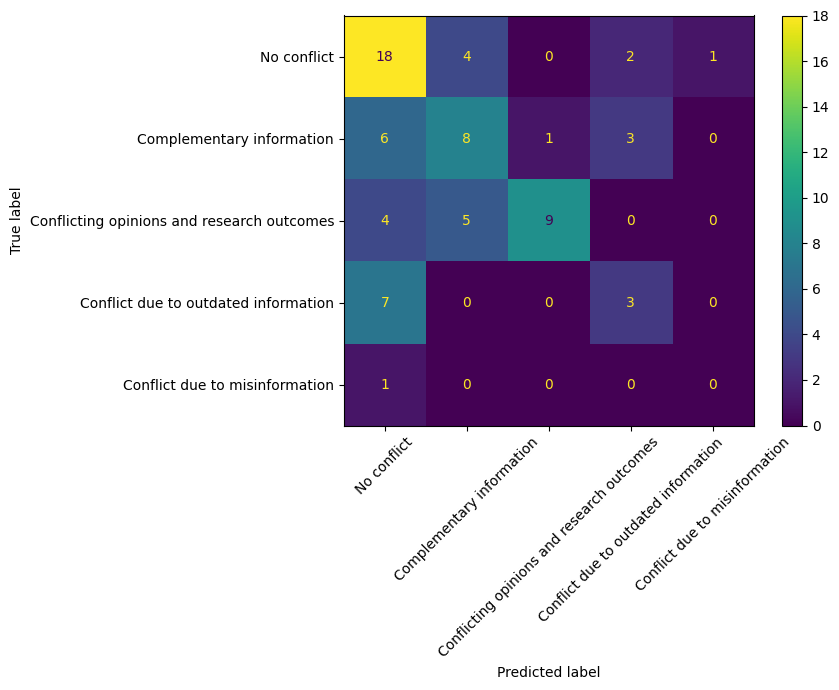

,model,split,n,accuracy,macro_f1_5class,macro_f1_4class,model_snapshot,prompt_sha256,classifier_config_hash,input_tokens_total,output_tokens_total
0,Prompted GPT-4o,final_test,72,0.527778,0.404699,0.505874,gpt-4o-2024-08-06,9b91a912cda2e1d974b3f9892b0b5e28953394fab3fdc8...,d835d3cde74ac59587a3d1196ab1eae40bf4fae75d412c...,251040,587


Saved: /Users/GXM/03-trimester 2/AIML339/Assignment/7/prompted_llm_final_test_predictions.csv /Users/GXM/03-trimester 2/AIML339/Assignment/7/prompted_llm_final_test_metrics.csv


In [6]:
if len(label_map) != len(run_df):
    print(f"Predictions incomplete: {len(label_map)}/{len(run_df)}. Enable RUN_API to request missing labels.")
else:
    scores_df = run_df[["example_id", "question", "gold_label"]].copy()
    scores_df["llm_predicted_label"] = scores_df.example_id.map(
        lambda i: label_map[int(i)]["llm_predicted_label"])
    scores_df["correct"] = scores_df.gold_label == scores_df.llm_predicted_label
    for field in ("classifier_input_tokens", "classifier_output_tokens"):
        scores_df[field] = scores_df.example_id.map(lambda i: label_map[int(i)].get(field))

    result = classification_metrics(scores_df.gold_label, scores_df.llm_predicted_label)
    print("Classification scores:", result)
    print(classification_report(scores_df.gold_label, scores_df.llm_predicted_label,
                                labels=LABELS, zero_division=0))

    cm = confusion_matrix(scores_df.gold_label, scores_df.llm_predicted_label, labels=LABELS)
    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, xticks_rotation=45)
    fig.tight_layout()
    plt.show()

    prediction_path = OUTPUT_DIR / f"prompted_llm_{RUN_MODE}_predictions.csv"
    summary_path = OUTPUT_DIR / f"prompted_llm_{RUN_MODE}_metrics.csv"
    scores_df.to_csv(prediction_path, index=False)
    summary = pd.DataFrame([{
        "model": "Prompted GPT-4o", "split": RUN_MODE, **result,
        "model_snapshot": LLM_MODEL,
        "prompt_sha256": PROMPT_TEXT_SHA256,
        "classifier_config_hash": llm_classifier_config_hash,
        "input_tokens_total": pd.to_numeric(scores_df.classifier_input_tokens, errors="coerce").sum(min_count=1),
        "output_tokens_total": pd.to_numeric(scores_df.classifier_output_tokens, errors="coerce").sum(min_count=1),
    }])
    summary.to_csv(summary_path, index=False)
    display(summary)
    print("Saved:", prediction_path, summary_path)